In [ ]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

Device: cuda


100.0%


Epoch 1/10, Loss: 1.7913
Epoch 2/10, Loss: 1.6661
Epoch 3/10, Loss: 1.6071
Epoch 4/10, Loss: 1.5634
Epoch 5/10, Loss: 1.5239
Epoch 6/10, Loss: 1.4898
Epoch 7/10, Loss: 1.4616
Epoch 8/10, Loss: 1.4349
Epoch 9/10, Loss: 1.4121
Epoch 10/10, Loss: 1.3913

Training Accuracy: 53.91%
Test Accuracy: 47.69%


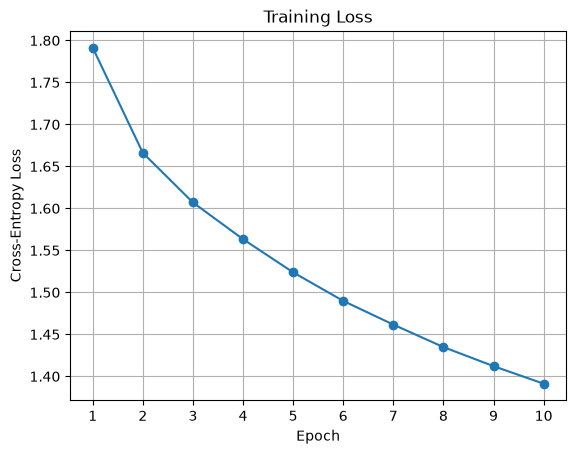

In [1]:
import math
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 1. Load CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

# 2. Initialize network parameters
Din = 3 * 32 * 32
H = 100
K = 10

W1 = torch.randn(Din, H, device=device) * math.sqrt(2 / (Din + H))
b1 = torch.zeros(H, device=device)
W2 = torch.randn(H, K, device=device) * math.sqrt(2 / (H + K))
b2 = torch.zeros(K, device=device)

epochs = 10
lr = 0.1
lr_decay = 0.9
loss_history = []

# 3. Training with manual backpropagation
for epoch in range(epochs):
    running_loss = 0.0

    for inputs, labels in trainloader:
        X = inputs.reshape(inputs.shape[0], -1).to(device)
        labels = labels.to(device)
        N = X.shape[0]

        hidden = torch.sigmoid(X @ W1 + b1)
        logits = hidden @ W2 + b2

        loss = F.cross_entropy(logits, labels)

        probabilities = torch.softmax(logits, dim=1)
        targets = F.one_hot(labels, num_classes=K).float()
        d_logits = (probabilities - targets) / N

        dW2 = hidden.T @ d_logits
        db2 = d_logits.sum(dim=0)

        d_hidden = d_logits @ W2.T
        d_hidden_pre = d_hidden * hidden * (1 - hidden)

        dW1 = X.T @ d_hidden_pre
        db1 = d_hidden_pre.sum(dim=0)

        with torch.no_grad():
            W1 -= lr * dW1
            b1 -= lr * db1
            W2 -= lr * dW2
            b2 -= lr * db2

        running_loss += loss.item()

    epoch_loss = running_loss / len(trainloader)
    loss_history.append(epoch_loss)

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.4f}")
    lr *= lr_decay

# 4. Calculate accuracy
def calculate_accuracy(loader):
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            X = inputs.reshape(inputs.shape[0], -1).to(device)
            labels = labels.to(device)

            hidden = torch.sigmoid(X @ W1 + b1)
            logits = hidden @ W2 + b2
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

train_acc = calculate_accuracy(trainloader)
test_acc = calculate_accuracy(testloader)

print(f"\nTraining Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

# 5. Plot training loss
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

## Discussion

It can be observed that although the model's loss has been reduced with each epoch, the training and test accuracies are still low. This can be due to the model being too simple so that it underfits the dataset. Including more hidden layers can help achieve a greater accuracy.

Device: cuda


100.0%
100.0%
100.0%
100.0%


LeNet-5 | Epoch 1/10 | Train Loss: 0.1041 | Train Acc: 96.94% | Test Loss: 0.1018 | Test Acc: 96.88%
LeNet-5 | Epoch 2/10 | Train Loss: 0.0542 | Train Acc: 98.39% | Test Loss: 0.0588 | Test Acc: 98.16%
LeNet-5 | Epoch 3/10 | Train Loss: 0.0415 | Train Acc: 98.73% | Test Loss: 0.0486 | Test Acc: 98.39%
LeNet-5 | Epoch 4/10 | Train Loss: 0.0289 | Train Acc: 99.20% | Test Loss: 0.0415 | Test Acc: 98.77%
LeNet-5 | Epoch 5/10 | Train Loss: 0.0325 | Train Acc: 98.94% | Test Loss: 0.0444 | Test Acc: 98.59%
LeNet-5 | Epoch 6/10 | Train Loss: 0.0223 | Train Acc: 99.36% | Test Loss: 0.0407 | Test Acc: 98.74%
LeNet-5 | Epoch 7/10 | Train Loss: 0.0194 | Train Acc: 99.42% | Test Loss: 0.0391 | Test Acc: 98.82%
LeNet-5 | Epoch 8/10 | Train Loss: 0.0142 | Train Acc: 99.58% | Test Loss: 0.0390 | Test Acc: 98.74%
LeNet-5 | Epoch 9/10 | Train Loss: 0.0124 | Train Acc: 99.63% | Test Loss: 0.0367 | Test Acc: 98.76%
LeNet-5 | Epoch 10/10 | Train Loss: 0.0107 | Train Acc: 99.68% | Test Loss: 0.0356 | Test A

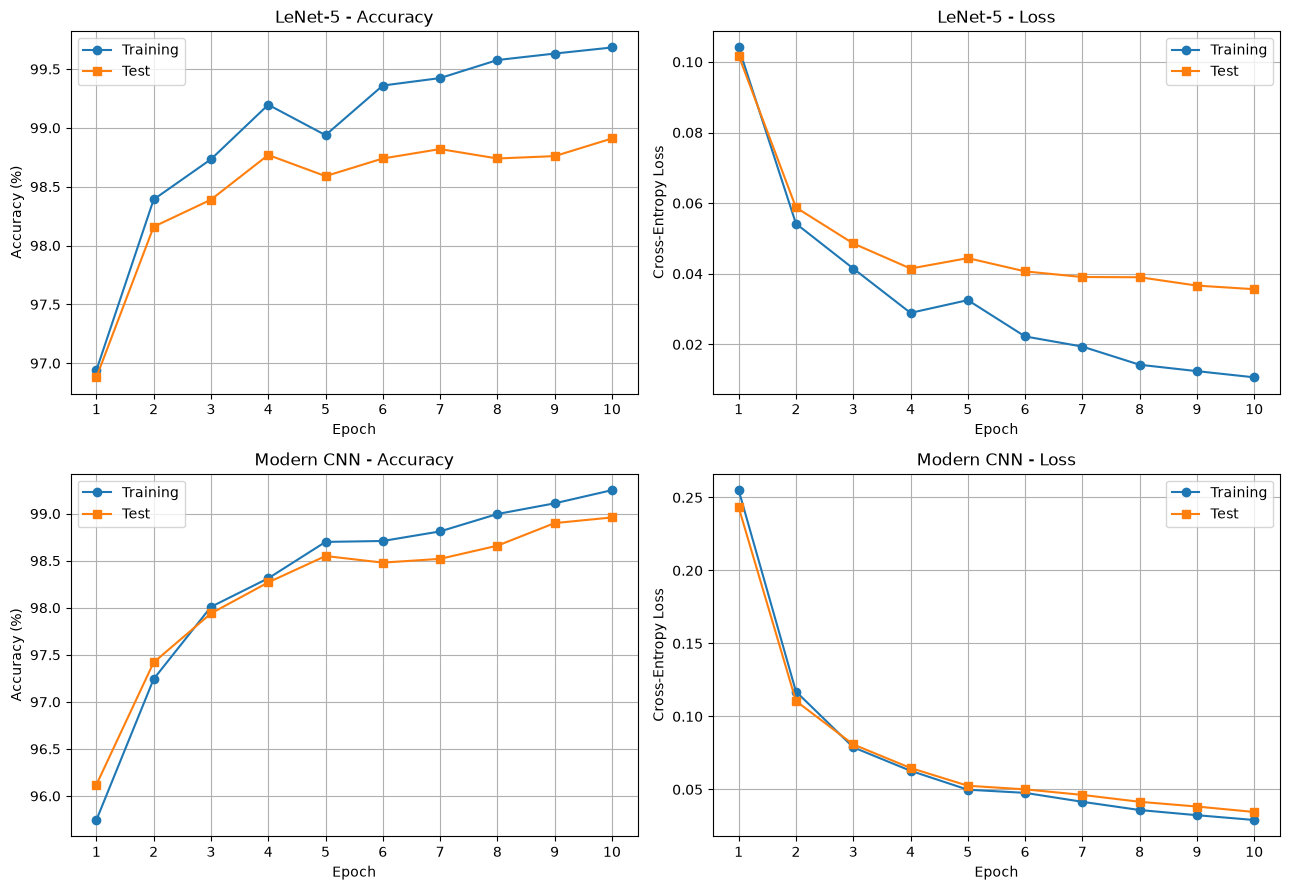

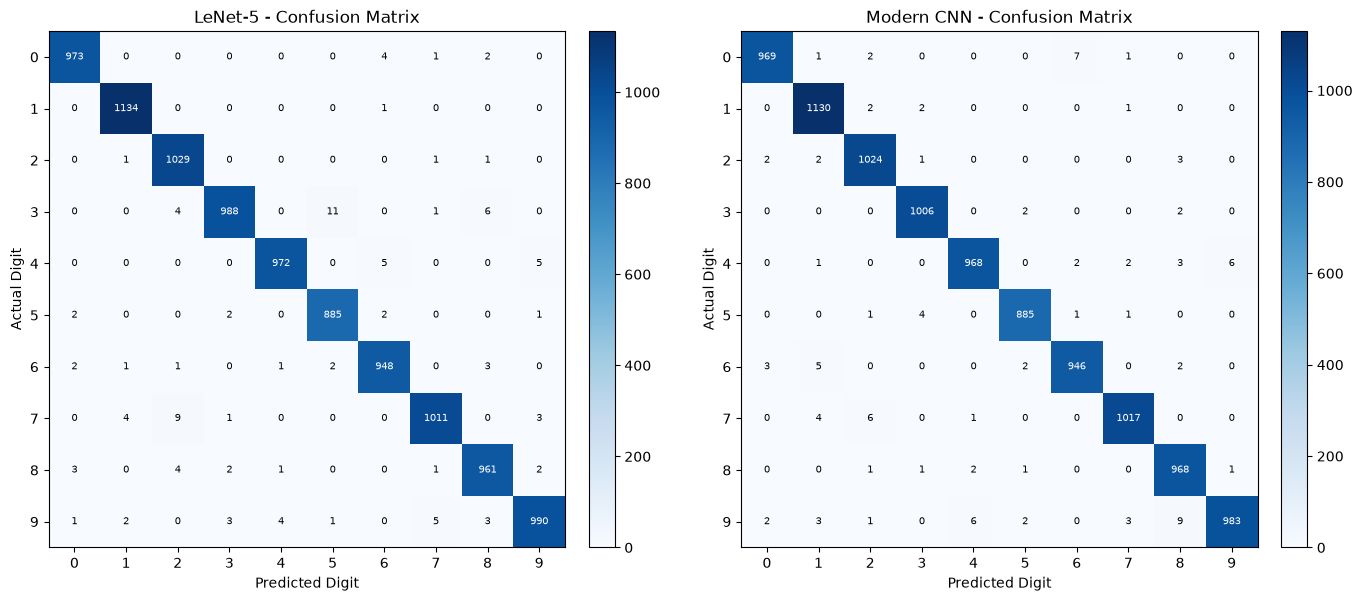

In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

batch_size = 128
epochs = 10
num_classes = 10

transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

trainset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

# LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(2, 2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Modern CNN: three convolutional layers
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


criterion = nn.CrossEntropyLoss()


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


def train_model(model, name):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_loss": [],
        "test_loss": [],
        "train_acc": [],
        "test_acc": []
    }

    for epoch in range(epochs):
        model.train()

        for images, labels in trainloader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, trainloader)
        test_loss, test_acc = evaluate(model, testloader)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.2f}%"
        )

    return model, history


# Train both models
lenet, lenet_history = train_model(LeNet5(), "LeNet-5")
cnn, cnn_history = train_model(ModernCNN(), "Modern CNN")


# Final results after 10 epochs
print("\nFinal Results")
print("-" * 45)

for name, history in [
    ("LeNet-5", lenet_history),
    ("Modern CNN", cnn_history)
]:
    print(
        f"{name}: Training Accuracy = "
        f"{history['train_acc'][-1]:.2f}%, "
        f"Test Accuracy = {history['test_acc'][-1]:.2f}%"
    )


# Plot per-epoch accuracy and loss
histories = [
    ("LeNet-5", lenet_history),
    ("Modern CNN", cnn_history)
]

epoch_numbers = range(1, epochs + 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for row, (name, history) in enumerate(histories):
    axes[row, 0].plot(
        epoch_numbers, history["train_acc"], marker="o", label="Training"
    )
    axes[row, 0].plot(
        epoch_numbers, history["test_acc"], marker="s", label="Test"
    )
    axes[row, 0].set_title(f"{name} - Accuracy")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Accuracy (%)")
    axes[row, 0].set_xticks(list(epoch_numbers))
    axes[row, 0].grid(True)
    axes[row, 0].legend()

    axes[row, 1].plot(
        epoch_numbers, history["train_loss"], marker="o", label="Training"
    )
    axes[row, 1].plot(
        epoch_numbers, history["test_loss"], marker="s", label="Test"
    )
    axes[row, 1].set_title(f"{name} - Loss")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Cross-Entropy Loss")
    axes[row, 1].set_xticks(list(epoch_numbers))
    axes[row, 1].grid(True)
    axes[row, 1].legend()

plt.tight_layout()
plt.show()


# Generate confusion matrices
@torch.no_grad()
def get_confusion_matrix(model, loader):
    model.eval()
    all_targets = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        predictions = model(images).argmax(dim=1)

        all_targets.append(labels)
        all_predictions.append(predictions.cpu())

    targets = torch.cat(all_targets)
    predictions = torch.cat(all_predictions)

    matrix = torch.bincount(
        targets * num_classes + predictions,
        minlength=num_classes ** 2
    ).reshape(num_classes, num_classes)

    return matrix.numpy()


lenet_cm = get_confusion_matrix(lenet, testloader)
cnn_cm = get_confusion_matrix(cnn, testloader)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name, matrix in [
    (axes[0], "LeNet-5", lenet_cm),
    (axes[1], "Modern CNN", cnn_cm)
]:
    im = ax.imshow(matrix, cmap="Blues")
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted Digit")
    ax.set_ylabel("Actual Digit")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    for i in range(10):
        for j in range(10):
            ax.text(
                j, i, str(matrix[i, j]),
                ha="center", va="center", fontsize=7,
                color="white" if matrix[i, j] > matrix.max() / 2 else "black"
            )

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()
